# State diagram — Final configurations

Final configurations ($T=2000$) for the 20 points in the $(\rho,\widetilde\kappa)$ plane: **density along the horizontal axis** and **interaction strength along the vertical axis**. We use one shared RNG seed to compare the same realization across parameter values. This is an illustrative atlas, not an ensemble average.

Cells are represented by their physical semi-axes and in-plane orientation, with periodic copies where needed. Round cells are gray; elongated cells have thin dark outlines and follow the **polar orientation** $\phi\in[0,2\pi)$ using the circular HSV legend in `circular_colormap.png` ($\phi=0$ at right, increasing counterclockwise).

To improve readability in dense regions, the HSV colors and the reference wheel are gently muted (same hue, lower saturation), while each ellipse receives a thin outline. The atlas is not a measure of spatial correlations.

In [3]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Ellipse
import numpy as np

workdir = Path.cwd().resolve()
root = workdir if (workdir / "ovito_final").is_dir() else workdir / "state_diagram"
ovito_root = root / "ovito_final"
assert ovito_root.is_dir(), f"OVITO directory not found: {ovito_root}"
wheel_path = root / "circular_colormap.png"
assert wheel_path.is_file(), f"Color-wheel image not found: {wheel_path}"

rhos = (0.60, 0.75, 0.85, 0.90, 0.98)
kappas = (0.75, 1.50, 2.50, 4.00)


def seed_from_filename(path):
    match = re.search(r"rng_seed=(\d+)\.200000$", path.name)
    if match is None:
        raise ValueError(f"Unexpected OVITO filename: {path.name}")
    return int(match.group(1))


files_by_point = {}
for rho in rhos:
    for kappa in kappas:
        rho_dir = f"rho_{rho:.2f}".replace(".", "_")
        kappa_dir = f"krep_{kappa:.2f}".replace(".", "_")
        folder = ovito_root / rho_dir / kappa_dir / "ovito"
        paths = sorted(folder.glob("*.200000"))
        if not paths:
            raise FileNotFoundError(f"No final configuration in {folder}")
        files_by_point[rho, kappa] = {seed_from_filename(path): path for path in paths}

shared_seeds = sorted(set.intersection(*(set(files) for files in files_by_point.values())))
assert shared_seeds, "No RNG seed is shared by all 20 parameter points."

seed_index = 0  # Change this index to inspect a different shared realization.
selected_seed = shared_seeds[seed_index]
print(f"Found {len(shared_seeds)} shared seeds. Selected seed: {selected_seed}")

Found 64 shared seeds. Selected seed: 7713914261614


## Spatial atlas

The files are extended XYZ: `Lattice` specifies the periodic square, `aspherical_shape` gives the semi-axes, and the quaternion yields $\phi=2\operatorname{atan2}(q_z,q_w)$. The supplied color wheel is an HSV orientation key: $0$ points right, $\pi/2$ points up, and opposite polar orientations receive different colors.

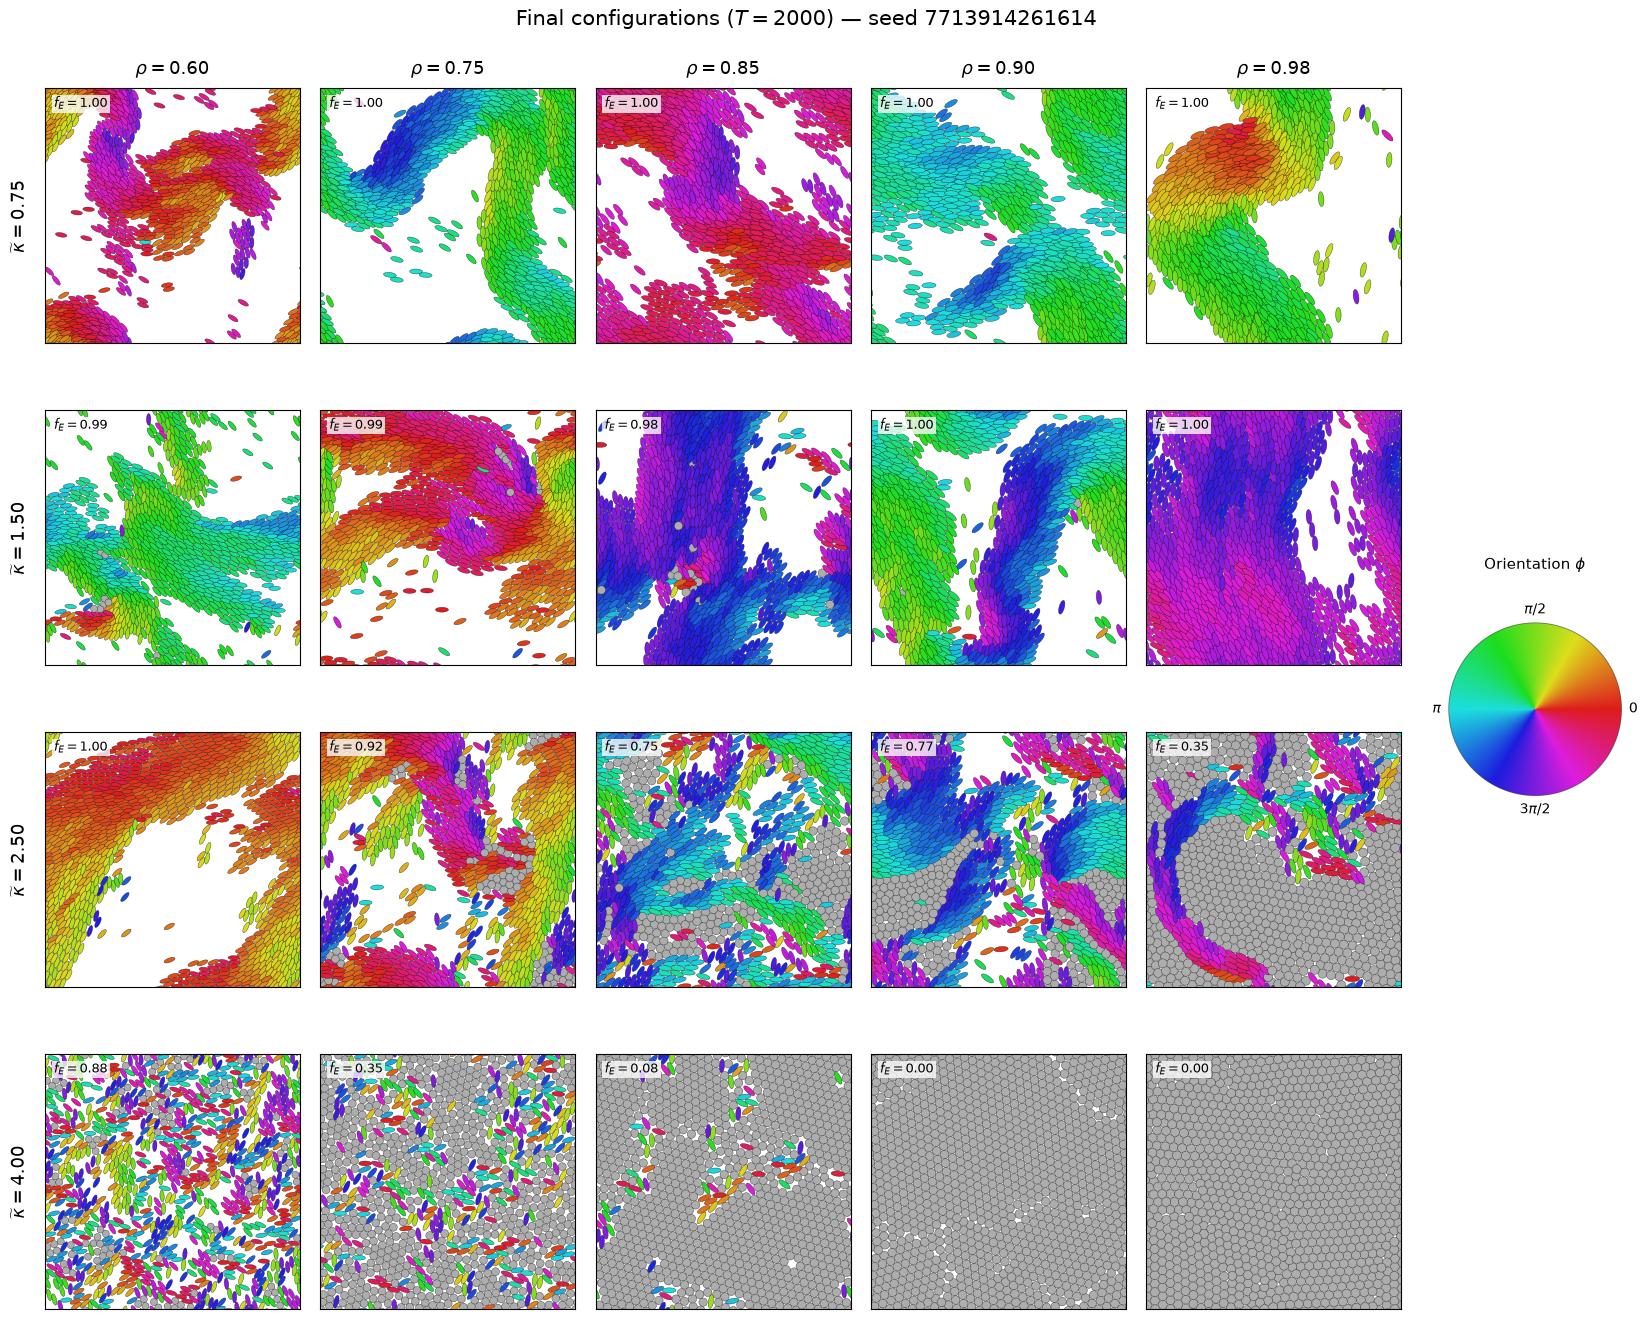

In [4]:
def load_final_configuration(path):
    with path.open() as stream:
        number_of_cells = int(stream.readline().strip())
        header = stream.readline()

    match = re.search(r'Lattice="([^"]+)"', header)
    if match is None:
        raise ValueError(f"Missing Lattice field in {path}")
    lattice = np.fromstring(match.group(1), sep=" ")
    if lattice.size != 9 or not np.isclose(lattice[0], lattice[4]):
        raise ValueError(f"Expected a square 2D periodic box in {path}")
    side = float(lattice[0])

    # Numeric columns after species:
    # x, y, z, a, b, c, qx, qy, qz, qw, Color
    values = np.loadtxt(path, skiprows=2, usecols=range(1, 12), ndmin=2)
    if values.shape != (number_of_cells, 11):
        raise ValueError(f"Unexpected particle count / format in {path}: {values.shape}")

    x, y = values[:, 0], values[:, 1]
    a, b = values[:, 3], values[:, 4]
    phi = np.mod(2.0 * np.arctan2(values[:, 8], values[:, 9]), 2.0 * np.pi)
    elongated = ~np.isclose(a, b, rtol=1e-6, atol=1e-6)

    return side, x, y, a, b, phi, elongated


# Keep the hue--orientation correspondence, but mute the fully saturated HSV colors.
# The same transform is applied to the circular color key below.
COLOR_STRENGTH = 0.76    # 1.0 = original HSV; lower values = softer colors.
NEUTRAL_GRAY = 0.46
EDGE_WIDTH = 0.33        # points; small enough for dense arrangements.
EDGE_ALPHA = 0.72


def muted_colors(rgba):
    rgba = np.array(rgba, copy=True)
    rgba[..., :3] = (COLOR_STRENGTH * rgba[..., :3]
                     + (1.0 - COLOR_STRENGTH) * NEUTRAL_GRAY)
    return rgba


def draw_configuration(ax, configuration, cmap):
    side, x, y, a, b, phi, elongated = configuration
    facecolors = muted_colors(cmap(phi / (2.0 * np.pi)))
    facecolors[~elongated] = (0.68, 0.68, 0.68, 1.0)

    patches, patch_colors = [], []
    for i in range(len(x)):
        xi, yi = x[i] % side, y[i] % side
        angle = np.rad2deg(phi[i])
        # Repeat only cells whose ellipse might cross a periodic boundary.
        # a is the largest semi-axis because aspect ratio >= 1.
        dx = [0.0]
        dy = [0.0]
        if xi < a[i]:
            dx.append(side)
        if xi > side - a[i]:
            dx.append(-side)
        if yi < a[i]:
            dy.append(side)
        if yi > side - a[i]:
            dy.append(-side)
        for offset_x in dx:
            for offset_y in dy:
                patches.append(Ellipse(
                    (xi + offset_x, yi + offset_y),
                    width=2.0 * a[i], height=2.0 * b[i], angle=angle,
                ))
                patch_colors.append(facecolors[i])

    collection = PatchCollection(
        patches,
        facecolor=patch_colors,
        edgecolor=(0.06, 0.06, 0.06, EDGE_ALPHA),
        linewidths=EDGE_WIDTH,
        rasterized=True,
    )
    ax.add_collection(collection)
    ax.set_xlim(0, side)
    ax.set_ylim(0, side)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.text(
        0.035, 0.965, rf"$f_E={elongated.mean():.2f}$",
        transform=ax.transAxes, va="top", ha="left", fontsize=9,
        bbox={"facecolor": "white", "alpha": 0.78, "edgecolor": "none", "pad": 1.5},
    )

# HSV follows the supplied wheel: red at 0, green at 2π/3,
# cyan at π, blue at 4π/3 and red again at 2π.
cmap = plt.get_cmap("hsv")
fig, axes = plt.subplots(len(kappas), len(rhos), figsize=(17.5, 14))

for row, kappa in enumerate(kappas):
    for col, rho in enumerate(rhos):
        ax = axes[row, col]
        path = files_by_point[rho, kappa][selected_seed]
        draw_configuration(ax, load_final_configuration(path), cmap)
        if row == 0:
            ax.set_title(rf"$\rho={rho:.2f}$", fontsize=13, pad=10)
        if col == 0:
            ax.set_ylabel(rf"$\widetilde{{\kappa}}={kappa:.2f}$", fontsize=13, labelpad=12)

fig.subplots_adjust(left=0.065, right=0.84, top=0.94, bottom=0.045,
                    wspace=0.08, hspace=0.12)

# Show the user's wheel as a legend; the cell colors use the matching HSV map.
wheel = muted_colors(plt.imread(wheel_path))
wheel_ax = fig.add_axes([0.865, 0.42, 0.103, 0.13])
wheel_ax.imshow(wheel)
wheel_ax.axis("off")
fig.text(0.9165, 0.585, r"Orientation $\phi$", ha="center", fontsize=11)
wheel_ax.text(1.02, 0.5, r"$0$", transform=wheel_ax.transAxes,
              va="center", ha="left", fontsize=10)
wheel_ax.text(0.5, 1.01, r"$\pi/2$", transform=wheel_ax.transAxes,
              va="bottom", ha="center", fontsize=10)
wheel_ax.text(-0.02, 0.5, r"$\pi$", transform=wheel_ax.transAxes,
              va="center", ha="right", fontsize=10)
wheel_ax.text(0.5, -0.02, r"$3\pi/2$", transform=wheel_ax.transAxes,
              va="top", ha="center", fontsize=10)

fig.suptitle(rf"Final configurations ($T=2000$) — seed {selected_seed}",
             fontsize=15, y=0.985)
plt.show()

The atlas is a **qualitative** comparison of one realization per point. Spatial alignment does not by itself establish coherent motion or dynamical arrest. We will use ensemble observables to characterize states and examine other seeds only where needed.